# Areas from polygons: `from_geodataframe`

Often the areas aren't in a table. What you have is a map: a shapefile or GeoJSON of
islands, reserves, counties or habitat patches, and a species count for each polygon.
`from_geodataframe()` turns that into the `area` and `species` columns `sars` works
with, measuring each area from the polygon itself.

This notebook does it end to end with real polygons: ten counties of the southern
Appalachians, whose amphibian species counts and areas were published by Stout,
Jessee & McMeen (2025) and are the data of the
[Appalachian amphibians example](appalachian.ipynb). Having published areas means the
computed ones can be checked. The step that matters most is the one before the
function call: putting the polygons in a coordinate system where area means something.

The notebook is about the mechanics. Ten counties of similar size make a poor
species–area dataset, as the last section shows.

It needs the `geo` extra, which installs geopandas and shapely:

```bash
pip install sars[geo]
```

In [1]:
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sars

## The polygons

`data/appalachian_counties.geojson` holds ten county outlines from Natural Earth's
1:10m admin-2 (counties) layer, which is in the public domain. Each has the county's
name and its state, and nothing else.

In [2]:
counties = gpd.read_file("data/appalachian_counties.geojson")
counties.drop(columns="geometry")

,county,state
0,Unicoi,TN
1,Whitfield,GA
2,Watauga,NC
3,Anderson,TN
4,Murray,GA
5,Fannin,GA
6,Polk,TN
7,Hamilton,TN
8,Sevier,TN
9,Buncombe,NC


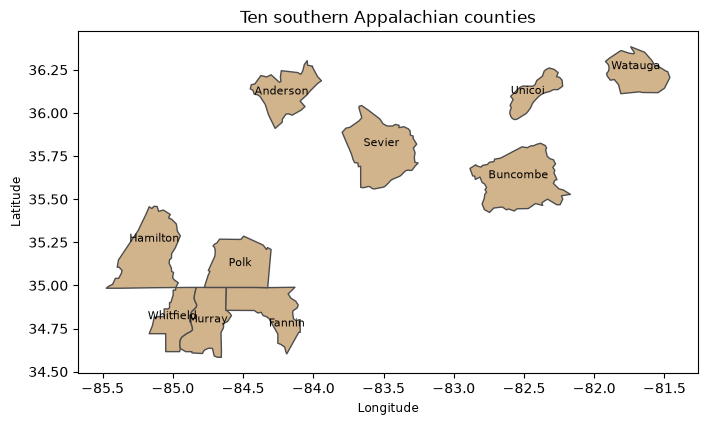

In [3]:
ax = counties.plot(color="tan", edgecolor="0.3", figsize=(8, 5))
for name, point in zip(counties["county"], counties.representative_point()):
    ax.annotate(name, (point.x, point.y), ha="center", fontsize=8)
ax.set(xlabel="Longitude", ylabel="Latitude", title="Ten southern Appalachian counties")
plt.show()

## Attaching the species counts

The counts are in the table used by the Appalachian example. Its `locality` column
names ten of its 26 sites as counties ("Unicoi Co. TN", "Anderson County TN"). Split
those names into county and state, and join them to the polygons on both. The join is
checked, not assumed: `validate="one_to_one"` fails if a county matches two rows, and
the assertion fails if one matches none.

In [4]:
table = pd.read_csv("data/appalachian_island.csv")
names = table["locality"].str.extract(r"^(?P<county>[A-Za-z ]+) (?:Co\.|County) (?P<state>[A-Z]{2})$")
county_rows = table.join(names).dropna(subset="county")

sites = counties.merge(county_rows, on=["county", "state"], how="left", validate="one_to_one")
assert sites["amphibians"].notna().all() and len(sites) == len(county_rows) == 10
sites[["county", "state", "locality", "area_km2", "amphibians"]]

,county,state,locality,area_km2,amphibians
0,Unicoi,TN,Unicoi Co. TN,481.70,27
1,Whitfield,GA,Whitfield Co. GA,753.69,20
2,Watauga,NC,Watauga Co. NC,809.63,30
3,Anderson,TN,Anderson County TN,893.60,30
4,Murray,GA,Murray Co. GA,898.73,26
5,Fannin,GA,Fannin Co. GA,1015.28,19
6,Polk,TN,Polk Co. TN,1144.80,38
7,Hamilton,TN,Hamilton Co. TN,1491.80,32
8,Sevier,TN,Sevier Co. TN,1548.80,39
9,Buncombe,NC,Buncombe Co. NC,1709.40,36


## Why the coordinate system comes first

The file's coordinates are longitude and latitude in degrees, as GeoJSON requires.

In [5]:
sites.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

A polygon's area is computed from its coordinates, so here it comes out in square
degrees. geopandas will do the sum, with a warning:

In [6]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    square_degrees = sites.area
for w in caught:
    print("Warning:", w.message)
pd.DataFrame({"county": sites["county"], "area in square degrees": square_degrees.round(4)}).head(4)

,county,area in square degrees
0,Unicoi,0.0457
1,Whitfield,0.0682
2,Watauga,0.0816
3,Anderson,0.0903


Unicoi County, some 480 km² of mountains, has an "area" of 0.05. A square degree is not
a unit of area: a degree of longitude is 111 km at the equator, 91 km at these
counties' latitude and nothing at the poles, so the same number means different areas
in different places.

`from_geodataframe()` therefore refuses polygons whose coordinates are degrees instead
of returning those numbers.

In [7]:
try:
    sars.from_geodataframe(sites, species_col="amphibians")
except ValueError as err:
    print("ValueError:", err)

ValueError: The GeoDataFrame's CRS (WGS 84) is geographic: its coordinates are degrees, and areas computed from it are meaningless. Reproject to an equal-area projected CRS first, e.g. gdf.to_crs("EPSG:6933"), or pass area_col to use areas from a column.


The fix is to reproject. But not to just any projection: map projections can't keep
everything true at once, and many of the ones in everyday use preserve shape at the
expense of area. For measuring area, use an **equal-area** projection. Two choices
here are EPSG:5070, the Albers equal-area projection used for maps of the contiguous
United States, and EPSG:6933, a cylindrical equal-area projection that works anywhere
in the world. Compare them with Web Mercator (EPSG:3857), the projection of online
maps, which is also "projected" and in metres:

In [8]:
pd.DataFrame({
    "county": sites["county"],
    "Albers (EPSG:5070)": sites.to_crs("EPSG:5070").area / 1e6,
    "cylindrical (EPSG:6933)": sites.to_crs("EPSG:6933").area / 1e6,
    "Web Mercator (EPSG:3857)": sites.to_crs("EPSG:3857").area / 1e6,
}).round(1)

,county,Albers (EPSG:5070),cylindrical (EPSG:6933),Web Mercator (EPSG:3857)
0,Unicoi,456.6,456.6,701.1
1,Whitfield,692.7,692.7,1029.9
2,Watauga,813.9,814.0,1253.5
3,Anderson,902.0,902.0,1385.1
4,Murray,950.1,950.1,1412.0
5,Fannin,1012.8,1012.8,1507.9
6,Polk,1135.1,1135.1,1700.5
7,Hamilton,1494.1,1494.0,2241.7
8,Sevier,1540.1,1540.1,2345.3
9,Buncombe,1705.8,1705.7,2586.4


The two equal-area projections agree to a tenth of a square kilometre. Web Mercator
makes every county half as large again as it is, and nothing warns you: it stretches
distances by 1/cos(latitude), which at 35° to 36° north inflates areas by about 50%.
`from_geodataframe()` can tell degrees from metres, but it cannot tell a projection
that distorts area from one that doesn't. That choice is yours.

In [9]:
equal_area = sites.to_crs("EPSG:5070")
print(equal_area.crs.name, "| unit:", equal_area.crs.axis_info[0].unit_name)

NAD83 / Conus Albers | unit: metre


## From polygons to a SAR table

Now one call does it. `crs_units` names the unit you want the areas in: `"km2"` (the
default), `"ha"` or `"m2"`.

In [10]:
data = sars.from_geodataframe(equal_area, species_col="amphibians", crs_units="km2")
data

,area,species
0,456.625238,27
1,692.676338,20
2,813.949859,30
3,901.970474,30
4,950.096627,26
5,1012.773749,19
6,1135.144305,38
7,1494.130131,32
8,1540.061612,39
9,1705.750293,36


## How good are the computed areas?

The paper's areas came along in the join, so the two can be set side by side.

In [11]:
compare = pd.DataFrame({
    "county": sites["county"],
    "computed km²": data["area"].round(1),
    "published km²": sites["area_km2"],
})
compare["computed / published"] = (compare["computed km²"] / compare["published km²"]).round(3)
compare

,county,computed km²,published km²,computed / published
0,Unicoi,456.6,481.70,0.948
1,Whitfield,692.7,753.69,0.919
2,Watauga,813.9,809.63,1.005
3,Anderson,902.0,893.60,1.009
4,Murray,950.1,898.73,1.057
5,Fannin,1012.8,1015.28,0.998
6,Polk,1135.1,1144.80,0.992
7,Hamilton,1494.1,1491.80,1.002
8,Sevier,1540.1,1548.80,0.994
9,Buncombe,1705.8,1709.40,0.998


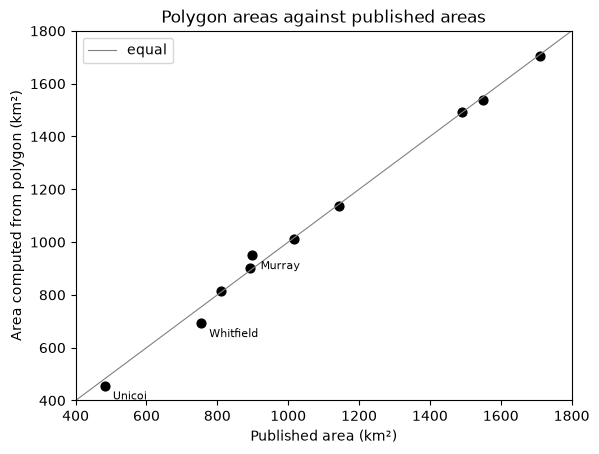

In [12]:
ax = compare.plot.scatter(x="published km²", y="computed km²", s=40, color="black")
lims = [400, 1800]
ax.plot(lims, lims, color="grey", linewidth=0.8, label="equal")
far_off = compare[(compare["computed / published"] - 1).abs() > 0.02]
for _, row in far_off.iterrows():
    ax.annotate(row["county"], (row["published km²"], row["computed km²"]), xytext=(6, -10),
                textcoords="offset points", fontsize=8)
ax.set(xlim=lims, ylim=lims, xlabel="Published area (km²)",
       ylabel="Area computed from polygon (km²)", title="Polygon areas against published areas")
ax.legend()
plt.show()

Seven of the ten computed areas are within 1% of the published ones. The other three
are 5% to 8% out: Unicoi and Whitfield come out smaller than published, Murray larger.

Differences of that size have ordinary explanations, and the projection isn't one of
them: an equal-area projection reproduces the area of the polygon it is given. A
1:10m outline is simplified (these counties have 27 to 66 vertices each), and a
published "area" may count land only or include water, or follow a boundary that has
since been resurveyed. A computed area is as good as the polygon behind it. If
the areas matter to a few percent, use boundaries digitised at a scale suited to the
sites, and find out what the published figure measures before treating either as the
truth.

## Fitting a model

`data` is an ordinary `sars` dataset. Fit the power law to it, and for comparison to
the published areas. Passing `area_col` makes `from_geodataframe()` take the areas from
a column instead of the geometry, and then the coordinate system doesn't matter.

In [13]:
published = sars.from_geodataframe(sites, species_col="amphibians", area_col="area_km2")
fit_computed = sars.sar_power(data)
fit_published = sars.sar_power(published)
pd.DataFrame(
    {
        name: {"c": fit.params["c"], "z": fit.params["z"], "R²": fit.r_squared}
        for name, fit in [("computed areas", fit_computed), ("published areas", fit_published)]
    }
).T.round(3)

,c,z,R²
computed areas,2.052,0.385,0.389
published areas,1.900,0.396,0.385


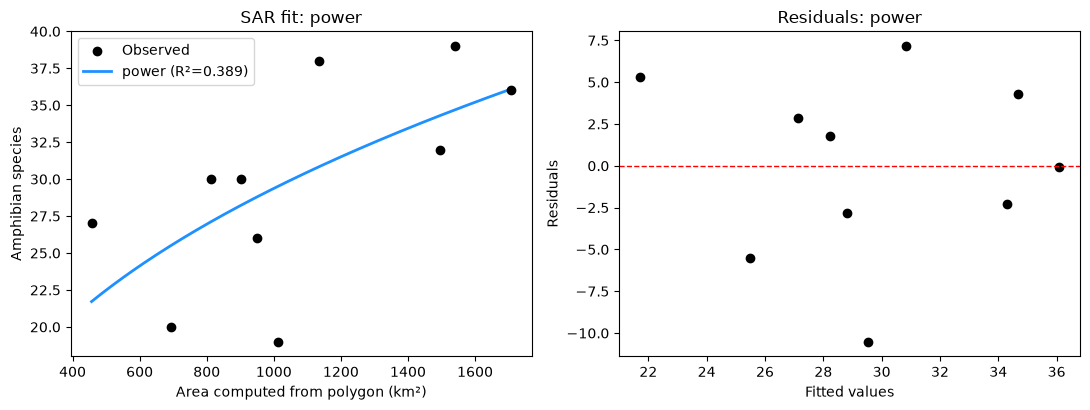

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sars.plot_fit(fit_computed, ax=axes[0])
sars.plot_residuals(fit_computed, ax=axes[1])
axes[0].set(xlabel="Area computed from polygon (km²)", ylabel="Amphibian species")
fig.tight_layout()
plt.show()

The two fits are nearly the same curve, so a few percent of error in the areas costs
little.

But don't read much into either. Area explains under 40% of the variation in richness
among these counties, and the parameters are not to be trusted: `z` is about 0.39 here
against 0.13 for all 26 sites in the [Appalachian example](appalachian.ipynb). The
reason is the design, not the method. The largest county is less than four times the
size of the smallest, and a species–area curve can't be pinned down over so short a
range, least of all with ten points whose richness depends heavily on which mountains
each county includes. The full dataset spans five orders of magnitude in area, and
that range, not the number of sites, is what lets it estimate a slope.

So take the mechanics from this notebook and the analysis from the other two.

## Your own data

The same steps work for any polygon file geopandas can read (shapefile, GeoPackage,
GeoJSON) with a column of species counts:

```python
sites = gpd.read_file("reserves.gpkg")
sites = sites.to_crs("EPSG:6933")  # or an equal-area CRS for your region
data = sars.from_geodataframe(sites, species_col="n_species", crs_units="ha")
multi = sars.sar_multi(data)
```

Some things to keep in mind.

- Reproject first, to an equal-area projection. `from_geodataframe()` raises an error
  for coordinates in degrees, and for a file with no coordinate system whose
  coordinates look like degrees, but the choice among projected systems is yours.
- A projected coordinate system measured in feet is handled: the areas are converted,
  so `crs_units="km2"` gives km² whatever the map's own unit.
- One row is one site. If a site is several polygons (an island with islets, a reserve
  in two parts), merge them first with `sites.dissolve(by="site_name", aggfunc="first")`.
- Every row needs an area greater than zero. Points, lines, empty geometries and
  degenerate polygons raise an error that names the rows.

### References

- Natural Earth. 1:10m cultural vectors, admin 2 counties. Free vector and raster map
  data at [naturalearthdata.com](https://www.naturalearthdata.com/), in the public domain.
- Stout JB, Jessee LD, McMeen JN (2025). Nested and island models for determining the
  species-area relationship of southern Appalachian amphibians. *Journal of North
  American Herpetology*, 2025(1), 1–7.
  [doi:10.17161/jnah.v2025i1.21974](https://doi.org/10.17161/jnah.v2025i1.21974)